# 2-01 일자별 발행 채권 — 그날 어떤 회사가 어떤 조건으로 채권을 냈나

**질문 예시:** "11월 23일에 발행된 회사채 보여줘", "이번 주에 CB 발행한 회사는?", "요즘 사모채 금리는 몇 %야?"

| 항목 | 데이터 출처 |
|---|---|
| 발행일별 채권 목록(발행회사·채권코드·채권명) | SEIBRO Open API `getBondIssuInfo` (`ISSU_DT`) |
| 발행금액·표면이자율·만기·모집방법·옵션·신용등급 | SEIBRO Open API `getBondStatInfo` (채권마다 1회) |
| 유형(CB·BW·EB·P-CBO·일반) | 채권명 표기 + `PARTICUL_BOND_KIND_TPCD` |

`getBondIssuInfo`는 **하루치만** 받습니다(기간 파라미터 없음). 패키지 함수 `get_issued_bonds(시작, 끝)`이 날짜마다 나눠 부르고,
`details=True`면 채권마다 상세를 한 번 더 불러 붙입니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/seibro-api/blob/main/scenarios/2_bond/01_issued_bonds_by_date.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `SEIBRO_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 첫 셀은 패키지를 설치하고, 두 번째 셀은 모든 시나리오에 공통인 준비 코드입니다(접어 두어도 됩니다). SEIBRO Open API 키는 [SEIBRO OpenPlatform](https://seibro.or.kr/OpenPlatform/)에서 신청합니다.

In [1]:
# Colab에서만: 패키지 설치 (로컬은 이 레포를 pip install -e . 로 설치해 두면 됨)
import sys
if "google.colab" in sys.modules:
    !pip -q install "git+https://github.com/beaten-by-the-market/seibro-api.git" koreanize-matplotlib

In [2]:
SECRETS = ['SEIBRO_API_KEY']
# ── SEIBRO 공통 셀 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 아래 SECRETS 이름으로 값을 넣고 "노트북 액세스"를 켜세요.
#        SEIBRO_API_KEY = 예탁결제원 SEIBRO Open API 인증키 (https://seibro.or.kr/OpenPlatform)
#        DART_API_KEY = OpenDART 인증키 (DART 데이터를 쓰는 노트북만)
#        KRX_ID / KRX_PW = KRX 정보데이터시스템 계정 (KRX 데이터를 쓰는 노트북만)
# 로컬: 환경변수 또는 작업 폴더(레포 루트)의 .env 를 읽습니다.
# 키·비밀번호 값은 어디에도 출력하지 않습니다. 있는지 여부만 보여 줍니다.
import os, sys, warnings
from datetime import date, datetime, timedelta

import pandas as pd

IN_COLAB = "google.colab" in sys.modules
warnings.filterwarnings("ignore", message="Unverified HTTPS request")

if IN_COLAB:
    from google.colab import userdata
    for _name in SECRETS:  # noqa: F821  (빌더가 이 셀 맨 위에 SECRETS 목록을 넣음)
        if os.environ.get(_name):
            continue
        try:
            _v = userdata.get(_name)
        except Exception:
            _v = None
        if not _v:
            from getpass import getpass
            _v = getpass(f"{_name}: ")
        os.environ[_name] = _v.strip()
else:
    from dotenv import find_dotenv, load_dotenv
    load_dotenv(find_dotenv(usecwd=True))

_missing = [
    n for n in SECRETS  # noqa: F821
    if not os.environ.get(n) and (IN_COLAB or not n.startswith("KRX_"))
]
if _missing:
    raise RuntimeError(f"{_missing} 가 없습니다. Colab Secrets 또는 .env 에 넣어 주세요.")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def won(v, digits=1):
    """원 → '1.2조' / '5,027억' / '3,400만'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


def shares(v):
    """주식수 → '23,607,980주'."""
    return "-" if v is None or pd.isna(v) else f"{int(v):,}주"


# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

def _status(n):
    if os.environ.get(n):
        return "있음"
    # 로컬에서 krx-data-api를 편집 설치(pip install -e)했다면 그 레포의 .env를 패키지가 직접 읽는다
    return "없음" if IN_COLAB or not n.startswith("KRX_") else "krx-data-api 자체 .env 사용"


print("SEIBRO 준비 완료", "(Colab)" if IN_COLAB else "(로컬)",
      "| " + ", ".join(f"{n}: {_status(n)}" for n in SECRETS))  # noqa: F821

SEIBRO 준비 완료 (로컬) | SEIBRO_API_KEY: 있음


In [3]:
DAY = "2026-11-23"                          # 자세히 볼 발행일
PERIOD = ("2026-11-02", "2026-11-24")       # 기간 요약 (평일만 조회)

from seibro_api import SeibroClient, get_issued_bonds

client = SeibroClient()   # 키는 환경변수 SEIBRO_API_KEY (위 준비 셀)

## 1. 하루치 목록
목록 자체는 칼럼이 5개뿐입니다(발행일·발행회사·고객번호·채권코드·채권명).

In [4]:
day_list = get_issued_bonds(DAY, client=client)
day_list.head(10)

[Seibro] 2026-11-23~2026-11-23 발행 채권 22건


,발행일,발행회사,발행회사고객번호,채권코드,채권명,유형
0,2026-11-23,가나안,7832,KR6063861GB4,가나안16(PCBO사모/콜),P-CBO
1,2026-11-23,대성산업,15778,KR6128821GB1,대성산업79(PCBO사모/콜),P-CBO
2,2026-11-23,보로노이,34136,KR6310211GB3,보로노이 5CB(사모/전환/풋),CB
3,2026-11-23,신원,927,KR6009271GB3,신원145(PCBO사모/콜),P-CBO
4,2026-11-23,씨앤투영,54850,KR60084L1GB0,씨앤투영 2CB(전환),CB
5,2026-11-23,씨제이씨지브이,9542,KR6079161GB1,씨제이 씨지브이46(PCBO사모/콜),P-CBO
6,2026-11-23,아모텍,8017,KR6052711GB4,아모텍9(PCBO사모/콜),P-CBO
7,2026-11-23,에어서울,55943,KR60134Z1GB4,에어서울4(사모/콜),일반
8,2026-11-23,에이제이네트웍스,12016,KR6095572GB9,AJ네트웍스107(PCBO사모/콜),P-CBO
9,2026-11-23,엔브이에이치코리아,8396,KR6067571GB5,엔브이에이치코리아26(PCBO사모/콜),P-CBO


상세를 붙이면 조건을 비교할 수 있습니다. 발행금액은 억 원, 만기는 발행일부터 만기일까지의 햇수입니다.

In [5]:
day = get_issued_bonds(DAY, details=True, client=client)
cols = ["발행회사", "채권명", "유형", "모집방법", "발행금액", "표면이자율", "만기(년)", "옵션", "순위", "KIS_등급", "NICE_등급", "KR_등급"]
view = day[cols].copy()
view["발행금액(억)"] = view.pop("발행금액") / 1e8
view = view.sort_values("발행금액(억)", ascending=False).reset_index(drop=True)
view.style.format({"발행금액(억)": "{:,.0f}", "표면이자율": "{:.3f}", "만기(년)": "{:.1f}"}, na_rep="")

[Seibro] 2026-11-23~2026-11-23 발행 채권 22건


  -> 상세 22/22건


,발행회사,채권명,유형,모집방법,표면이자율,만기(년),옵션,순위,KIS_등급,NICE_등급,KR_등급,발행금액(억)
0,한국수력원자력,한국수력원자력84-1,일반,공모,3.992,3.0,해당없음,선순위,AAA,AAA,AAA,800
1,보로노이,보로노이 5CB(사모/전환/풋),CB,사모,0.000,5.0,PUT,선순위,,,,527
2,폴라리스쉬핑,폴라리스쉬핑 43(연)(사모),일반,사모,6.563,2.0,해당없음,선순위,,,,300
3,종근당바이오,종근당바이오2(PCBO사모/콜),P-CBO,CBO기초사모,4.441,3.0,CALL,선순위,,,,300
4,케이알산업,케이알산업18(PCBO사모/콜),P-CBO,CBO기초사모,4.441,3.0,CALL,선순위,,,,300
5,씨제이씨지브이,씨제이 씨지브이46(PCBO사모/콜),P-CBO,CBO기초사모,6.782,3.0,CALL,선순위,,,,300
6,한국수력원자력,한국수력원자력84-2,일반,공모,4.058,5.0,해당없음,선순위,AAA,AAA,AAA,200
7,에이제이네트웍스,AJ네트웍스107(PCBO사모/콜),P-CBO,CBO기초사모,4.241,3.0,CALL,선순위,,,,170
8,탑솔라,탑솔라5(PCBO사모/콜),P-CBO,CBO기초사모,5.241,3.0,CALL,선순위,,,,150
9,아모텍,아모텍9(PCBO사모/콜),P-CBO,CBO기초사모,5.641,3.0,CALL,선순위,,,,140


In [6]:
def summarize(df):
    g = df.groupby("유형").agg(건수=("채권코드", "size"), 발행금액=("발행금액", "sum"),
                              평균금리=("표면이자율", "mean"), 평균만기=("만기(년)", "mean"))
    g.loc["합계"] = [len(df), df["발행금액"].sum(), df["표면이자율"].mean(), df["만기(년)"].mean()]
    g["발행금액(억)"] = g.pop("발행금액") / 1e8
    return g


print(f"{DAY} 발행 {len(day)}건, 총 {won(day['발행금액'].sum())}원")
summarize(day).style.format({"건수": "{:,.0f}", "발행금액(억)": "{:,.0f}", "평균금리": "{:.2f}%", "평균만기": "{:.1f}년"})

2026-11-23 발행 22건, 총 4,160억원


,건수,평균금리,평균만기,발행금액(억)
유형,,,,
CB,2,3.00%,4.0년,530
P-CBO,15,4.92%,3.0년,"2,110"
일반,5,5.46%,2.4년,"1,520"
합계,22,4.87%,3.0년,"4,160"


## 2. 기간 요약
같은 함수에 시작·끝을 주면 평일마다 한 번씩 부릅니다. 상세까지 받으면 채권 수만큼 호출이 더 늘어납니다(수십 건이면 1분 안쪽).

In [7]:
period = get_issued_bonds(*PERIOD, details=True, client=client)
summarize(period).style.format({"건수": "{:,.0f}", "발행금액(억)": "{:,.0f}", "평균금리": "{:.2f}%", "평균만기": "{:.1f}년"})

[Seibro] 2026-11-02~2026-11-24 발행 채권 280건


  [getBondStatInfo] 시도 1/3 실패: mismatched tag: line 13, column 119
  → 2초 후 재시도...


  -> 상세 280/280건


,건수,평균금리,평균만기,발행금액(억)
유형,,,,
BW,2,0.00%,17.5년,"1,060"
CB,21,0.81%,6.7년,"7,951"
EB,2,0.00%,5.0년,"5,163"
P-CBO,222,5.57%,2.6년,"5,271"
일반,33,5.70%,3.0년,"19,799"
합계,280,5.15%,3.1년,"39,244"


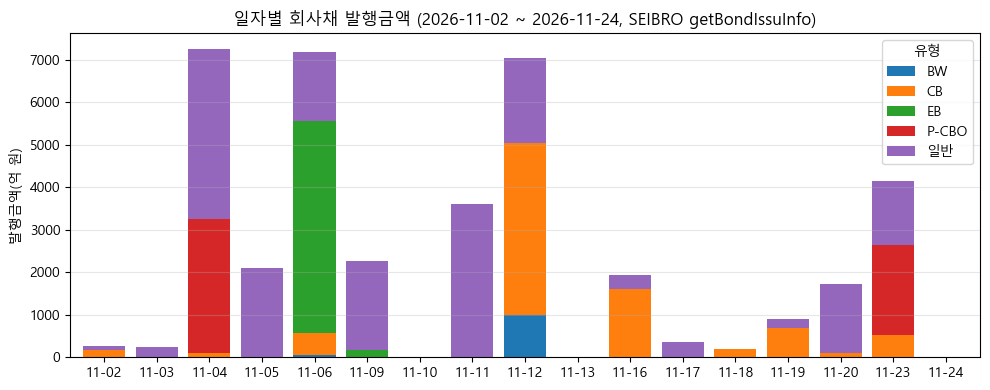

In [8]:
daily = period.pivot_table(index="발행일", columns="유형", values="발행금액", aggfunc="sum", fill_value=0) / 1e8
days = pd.bdate_range(*PERIOD)
daily = daily.reindex(days, fill_value=0)
ax = daily.plot(kind="bar", stacked=True, figsize=(10, 4), width=0.8)
ax.set_xticklabels([d.strftime("%m-%d") for d in daily.index], rotation=0)
ax.set_ylabel("발행금액(억 원)")
ax.set_title(f"일자별 회사채 발행금액 ({PERIOD[0]} ~ {PERIOD[1]}, SEIBRO getBondIssuInfo)")
ax.grid(axis="y", alpha=.3)
plt.tight_layout()

## 3. 기간 중 주식관련사채(CB·BW·EB)
주식으로 바뀔 수 있는 사채입니다. 발행회사의 희석 효과는 `1_stock/01_dilution` 노트북으로 이어서 볼 수 있습니다.

In [9]:
eq = period[period["유형"].isin(["CB", "BW", "EB"])].copy()
eq["발행금액(억)"] = eq["발행금액"] / 1e8
eq["발행일"] = eq["발행일"].dt.strftime("%Y-%m-%d")
eq[["발행일", "발행회사", "채권명", "유형", "채권종류", "모집방법", "발행금액(억)", "표면이자율", "만기(년)", "옵션"]] \
    .style.format({"발행금액(억)": "{:,.0f}", "표면이자율": "{:.2f}", "만기(년)": "{:.1f}"}, na_rep="")

,발행일,발행회사,채권명,유형,채권종류,모집방법,발행금액(억),표면이자율,만기(년),옵션
0,2026-11-02,국전,국전4CB(사모/전환/풋),CB,전환(CB),사모,170,0.00,5.0,PUT
47,2026-11-04,리메드,리메드4CB(사모/전환/풋),CB,전환(CB),사모,100,1.00,5.0,PUT
218,2026-11-06,다스코,다스코 8BW(사모/신/풋),BW,신주인수권(BW),사모,60,0.00,5.0,PUT
219,2026-11-06,블루엠텍,블루엠텍2CB(사모/전환/풋),CB,전환(CB),사모,360,0.00,7.0,PUT
220,2026-11-06,빛과전자,빛과전자19CB(사모/전환/풋),CB,전환(CB),사모,30,1.00,3.0,PUT
222,2026-11-06,에이엘티,에이엘티 8CB(사모/전환/풋),CB,전환(CB),사모,122,0.00,5.0,PUT
223,2026-11-06,엘에스전선,엘에스전선34EB(사모/교환/풋),EB,교환(EB),사모,"5,000",0.00,5.0,PUT
227,2026-11-09,케이지에코솔루션,케이지에코솔루션4EB(사모/교환/풋),EB,교환(EB),사모,163,0.00,5.0,PUT
233,2026-11-12,두산퓨얼셀,두산퓨얼셀15CB(신종)(사모/전환/콜),CB,전환(CB),사모,"3,000",0.00,30.0,CALL
234,2026-11-12,두산퓨얼셀,두산퓨얼셀16BW(신종)(사모/신/콜),BW,신주인수권(BW),사모,"1,000",0.00,30.0,CALL


## 결과 읽는 법과 한계
- **대상은 SEIBRO에 등록된 회사채**(일반 공모·사모, P-CBO 기초자산, CB·BW·EB, 일부 공기업 채권)입니다. 국고채·통안채·은행채·여전채가 다 들어 있는지는 이 API 문서로 확인되지 않았습니다. 시장 전체 발행 통계로 쓰지 마세요.
- **당일 발행분은 하루 늦게 잡히기도** 합니다. 기간 끝 날짜가 0건이면 다음 날 다시 확인하세요.
- `유형`은 채권명 괄호 표기(예: `5CB(사모/전환/풋)`, `(PCBO사모/콜)`)로 붙인 것입니다. 정식 구분은 `채권종류`(전환·교환·신주인수권) 칼럼을 보세요. P-CBO는 `채권종류`가 "해당없음"으로 나옵니다.
- `표면이자율`은 발행 조건입니다. 사모 CB·BW는 0~3%대가 흔한데, 주식 전환권의 대가라 일반 사채 금리와 바로 비교하면 안 됩니다.
- 신용등급은 공모채에만 대체로 있습니다. 사모채·P-CBO 기초채권은 비어 있는 게 정상입니다.
- `getBondStatInfo`가 일부 BW(신종 비분리형 등)에서 오류를 내면 그 채권은 상세 칼럼이 비어 있습니다.